## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [ ]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  27.3M      0 --:--:-- --:--:-- --:--:-- 27.3M


In [ ]:
pip install scanpy


In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [ ]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [ ]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [ ]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [ ]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [ ]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData?

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [ ]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [ ]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

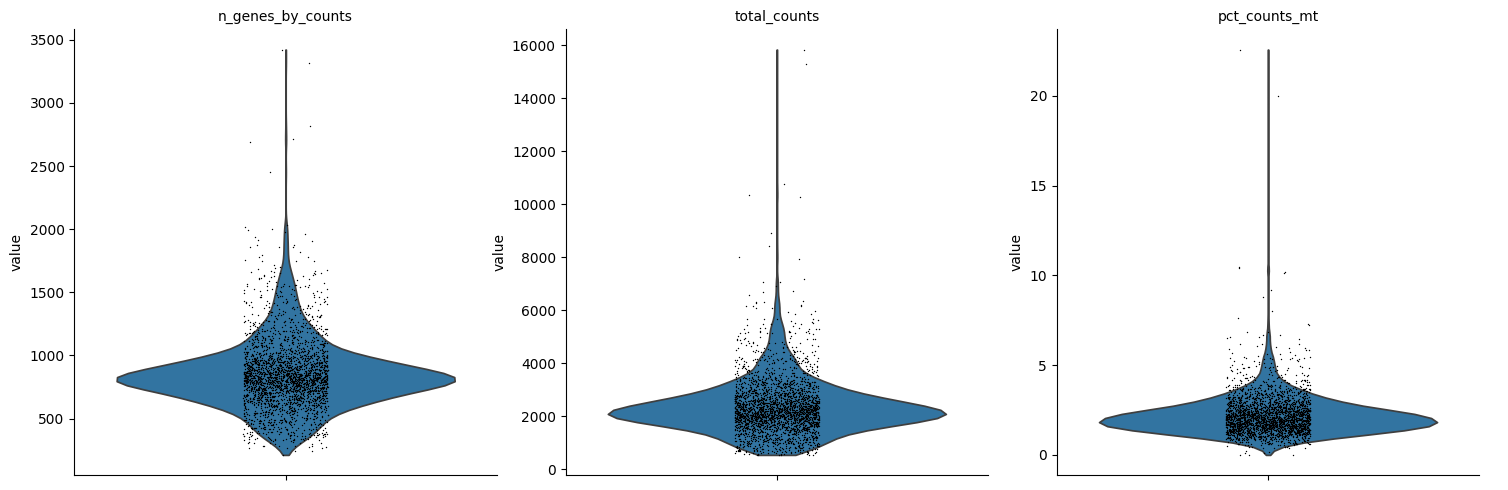

In [ ]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [ ]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [ ]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

In [ ]:
!pip install scikit-misc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 4.9 MB/s eta 0:00:00


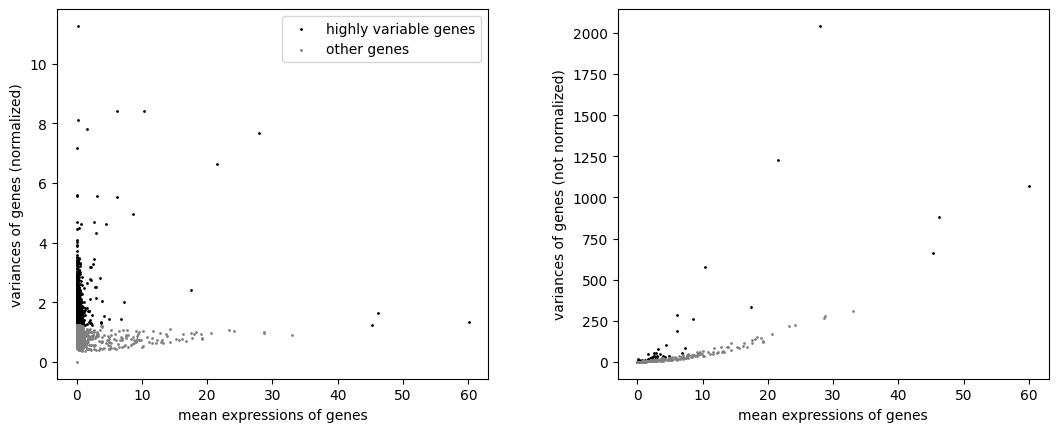

In [ ]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

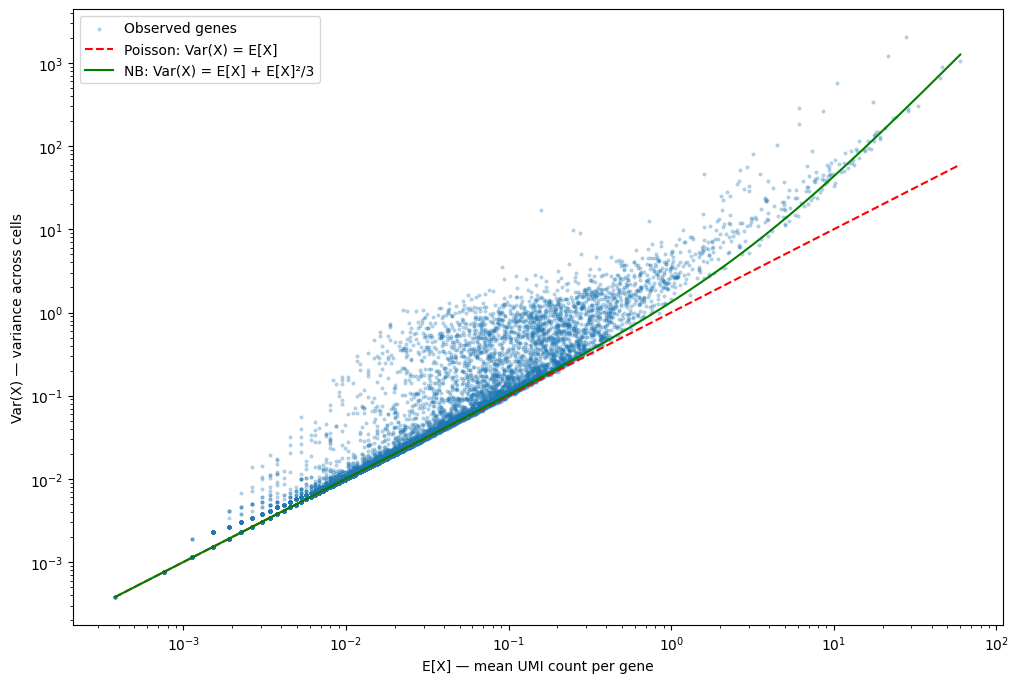

In [ ]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

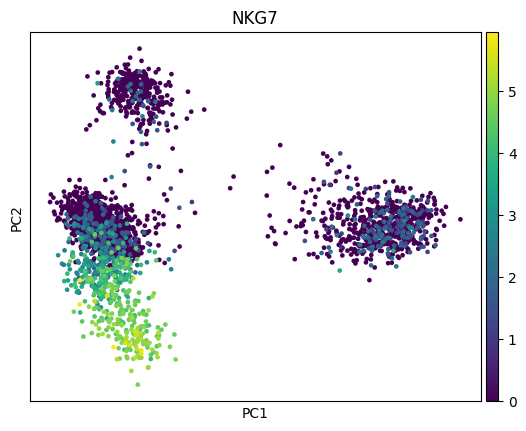

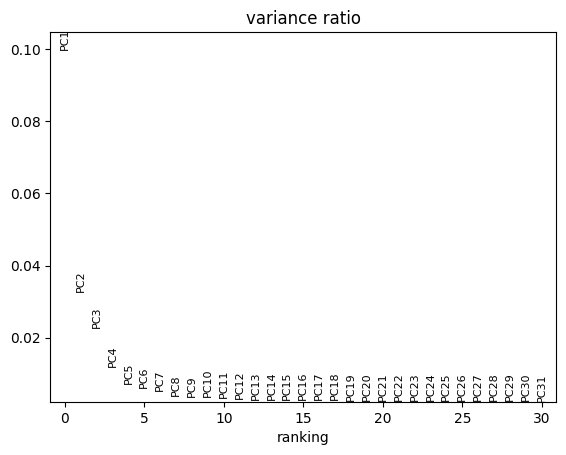

In [ ]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?

После фильтрации получили размер 2638 × 13714 (изначально была только основная матрица adata.X с сырыми UMI counts размером 2700 × 32 738 и столбец gene_ids в таблице генов), появились новые параметры: **obs** - метрики качества клеток (число обнаруженных генов, общее число UMI, доля митохондриальных UMI), **var** - характеристики генов (признак митохондриального гена (mt), признак высокой вариабельности, среднее и дисперсия экспрессии и тд), **uns** - параметры и служебные результаты отбора, **obsm** - координаты клеток в пространстве главных компонент, **varm** - нагрузки генов на главные компоненты, **layers** - копия сырых UMI counts, сохранённая до нормализации

* По каким генам можно ещё делать QC?   

Можно использовать рибосомальные, гены гемоглобинов или маркеры тромбоцитов
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?

Лучше использовать gtf/gff файл, тк в аннотации для каждого гена указаны хромосома и биотип, поэтому митохондриальные гены можно определить как все гены на хромосоме MT, а рибосомные по биотипу и описанию, не полагаясь на названия (они плохи тем что зависят от организма или может давать ложные совпадения)
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?

In [ ]:
raw = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
raw.var_names[raw.var_names.str.startswith("MT-")]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

На митохондриальной хромосоме человека 37 генов: 13 белок-кодирующих, 22 гена тРНК + 2 гена рРНК. В наших данных их 13 - только белок-кодирующие гены, генов тРНК и рРНК в матрице нет, потому что их не было в референсе, по которому считали экспрессию

При этом не каждый ген, начинающийся с MT - митохондриальный (например MT1A и MT2A это металлотионеины), поэтому искать нужно именно по "MT-". Кроме того, префикс MT- характерен для аннотации человека, у других организмов он может отличаться или отсутствовать

* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

У коров смешано 9 генов с MT-, 4 без префикса; у обезьянок тоже по-разному (шимпанзе как у человека, у макак без префикса), у собачек в текущей сборке Ensembl митохондриальной хромосомы нет вообще, только хромосомы 1–38, X, Y и неразмещённые фрагменты

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили.

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [ ]:
adata_qc = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
names = adata_qc.var_names

adata_qc.var["mt"] = names.str.startswith("MT-")
adata_qc.var["ribo"] = names.str.match(r"^RP[SL]\d+[AXYL]?L?\d*$|^RPLP\d$|^RPSA$")
adata_qc.var["hb"] = names.str.match(r"^HB[ABDEGMQZ]\d*$")
adata_qc.var["platelet"] = names.isin(["PPBP", "PF4"]) #маркер тромбоцитов

groups = ["mt", "ribo", "hb", "platelet"]
adata_qc.var[groups].sum()

mt          13
ribo        88
hb          10
platelet     2
dtype: int64

In [ ]:
#рассчитайте долю UMI
sc.pp.calculate_qc_metrics(adata_qc, qc_vars=groups, percent_top=None, log1p=False, inplace=True)

metrics = ["n_genes_by_counts", "total_counts"] + [f"pct_counts_{g}" for g in groups]
adata_qc.obs[metrics].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_genes_by_counts,2700.0,846.99,282.10,212.00,690.00,817.00,953.25,3422.00
total_counts,2700.0,2366.90,1094.26,548.00,1757.75,2197.00,2763.00,15844.00
pct_counts_mt,2700.0,2.22,1.17,0.00,1.54,2.03,2.64,22.57
pct_counts_ribo,2700.0,34.85,10.19,1.06,26.30,36.65,43.22,59.11
pct_counts_hb,2700.0,0.00,0.03,0.00,0.00,0.00,0.00,1.36
pct_counts_platelet,2700.0,0.03,0.48,0.00,0.00,0.00,0.00,10.98


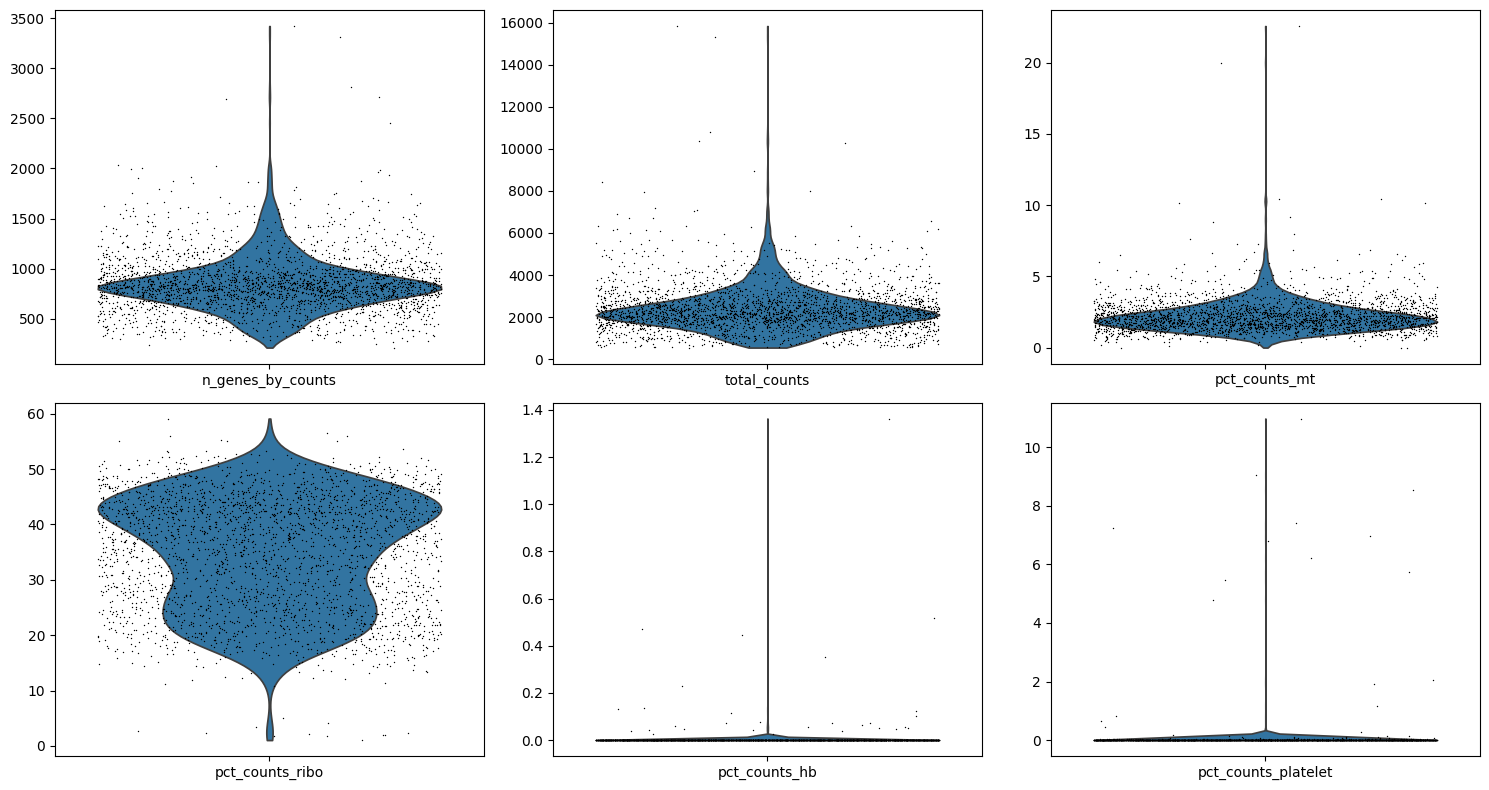

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, m in zip(axes.ravel(), metrics):
    sc.pl.violin(adata_qc, m, jitter=0.4, ax=ax, show=False)
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

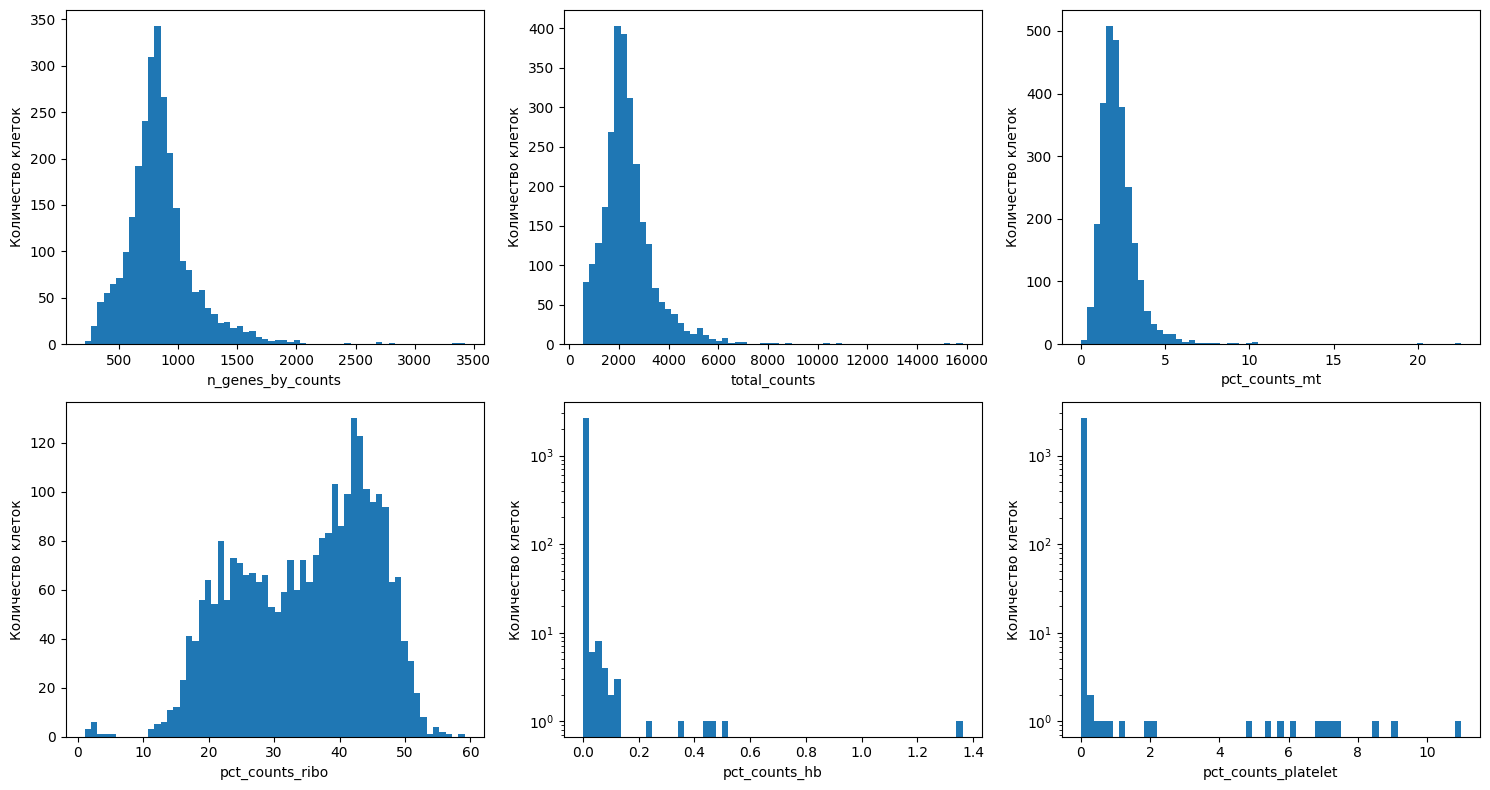

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, m in zip(axes.ravel(), metrics):
    ax.hist(adata_qc.obs[m], bins=60)
    ax.set_xlabel(m)
    ax.set_ylabel("Количество клеток")
    if m in ["pct_counts_hb", "pct_counts_platelet"]:
        ax.set_yscale("log")
fig.tight_layout()
plt.show()

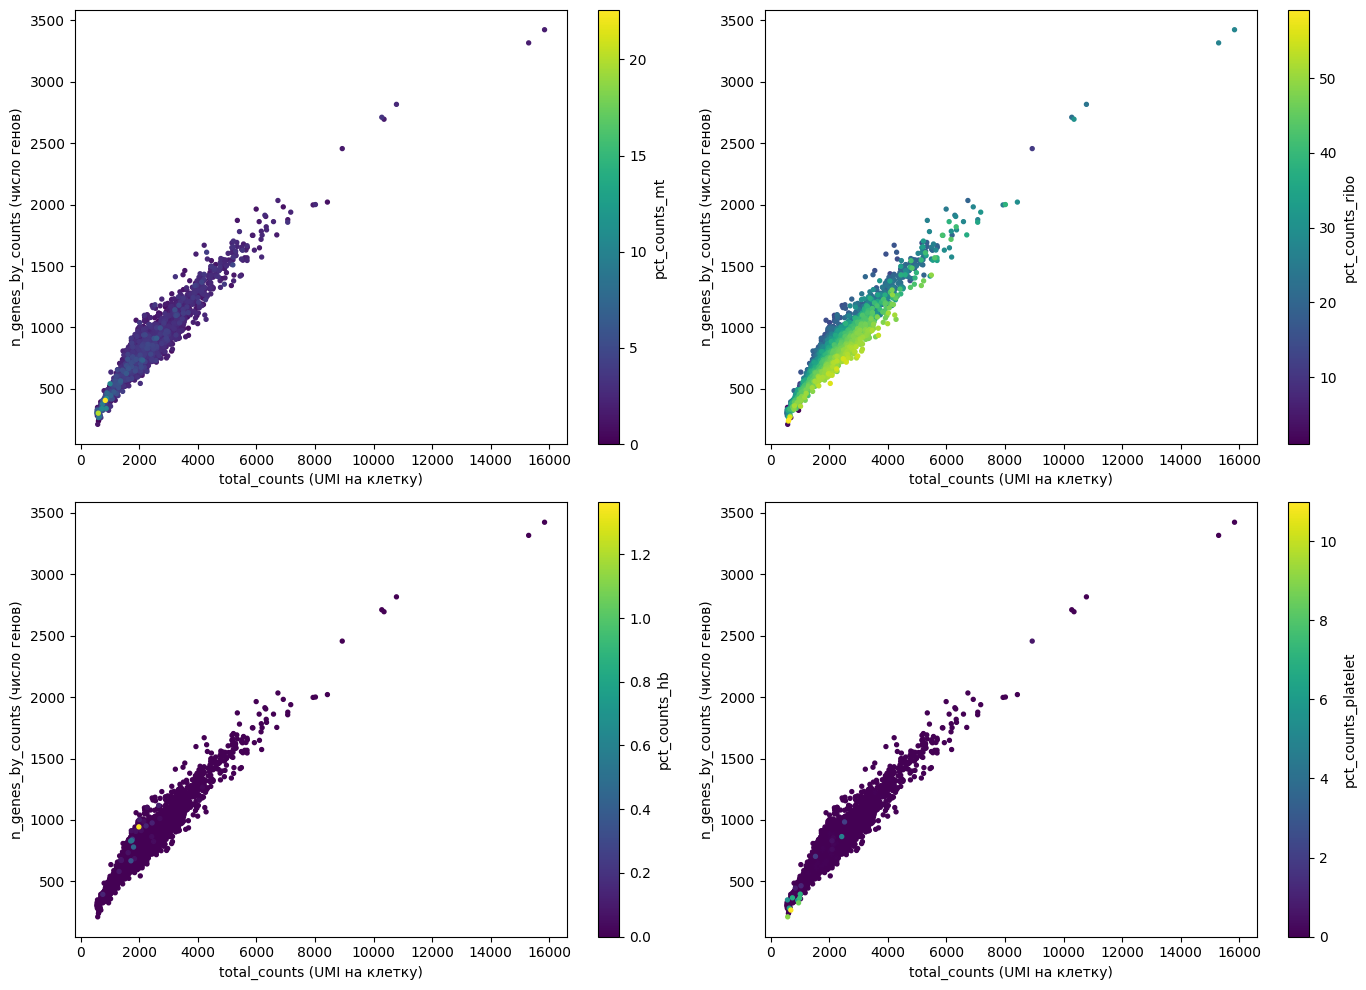

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, g in zip(axes.ravel(), groups):
    obs = adata_qc.obs.sort_values(f"pct_counts_{g}")
    points = ax.scatter(obs["total_counts"], obs["n_genes_by_counts"], c=obs[f"pct_counts_{g}"], s=8)
    fig.colorbar(points, ax=ax, label=f"pct_counts_{g}")
    ax.set_xlabel("total_counts (UMI на клетку)")
    ax.set_ylabel("n_genes_by_counts (число генов)")
fig.tight_layout()
plt.show()

In [ ]:
obs = adata_qc.obs
print("Генов > 2500:", (obs["n_genes_by_counts"] > 2500).sum())
print("Митохондриальных UMI > 5%:", (obs["pct_counts_mt"] > 5).sum())
print("Тромбоцитарных UMI > 5%:", (obs["pct_counts_platelet"] > 5).sum())
print("Гемоглобиновых UMI > 1%:", (obs["pct_counts_hb"] > 1).sum())
print("Рибосомных UMI < 10%:", (obs["pct_counts_ribo"] < 10).sum())

Генов > 2500: 5
Митохондриальных UMI > 5%: 57
Тромбоцитарных UMI > 5%: 10
Гемоглобиновых UMI > 1%: 1
Рибосомных UMI < 10%: 12


* Какие клетки выглядят подозрительными?

    Подозрительными выглядят несколько групп клеток. Пять клеток содержат более 2500 генов и 10–16 тысяч UMI при медиане 2197, на графике зависимости числа генов от числа UMI они лежат отдельно от основной массы, скорее всего они  являются дублетами. У 57 клеток доля митохондриальных UMI превышает 5%, и генов в них заметно меньше, чем в остальных - это мб повреждённые клетки. Ещё у 10 клеток более 5% UMI приходится на маркеры тромбоцитов PPBP и PF4,в этих клетках всего 212–397 генов и лишь 1–5% рибосомных UMI, что соответствует тромбоцитам

* Какие метрики могут свидетельствовать о низком качестве клетки?

    О низком качестве клетки могут свидетельствовать малое число обнаруженных генов и UMI либо наоборот аномально большое их число, высокая доля митохондриальных UMI (повреждение мембраны, при котором цитоплазматическая мРНК теряется, а митохондриальная сохраняется) + высокая доля гемоглобинов (примесь эритроцитов)

* Почему высокая доля определённой группы генов не всегда означает плохое качество?

    Высокая доля группы генов может объясняться типом клетки, а не плохим качеством (доля рибосомных UMI у лимфоцитов около 40%, а у моноцитов около 24%. Высокая доля маркеров PPBP и PF4 указывает на тромбоциты, а гемоглобинов на эритроциты) Митохондриальные гены в норме составляют большую долю в клетках тканей с активным энергетическим обменом, например сердца и печени, поэтому пороги фильтрации нужно подбирать для конкретного образца, чтобы не потерять настоящие клеточные популяции

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`.

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


In [ ]:
#отбор тремя методами
adata.var["hvg_seurat_v3"] = adata.var["highly_variable"].copy()

sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000)
adata.var["hvg_seurat"] = adata.var["highly_variable"].copy()

sc.experimental.pp.highly_variable_genes(adata, flavor="pearson_residuals", layer="counts", n_top_genes=2000)
adata.var["hvg_pearson"] = adata.var["highly_variable"].copy()

methods = ["hvg_seurat_v3", "hvg_seurat", "hvg_pearson"]
adata.var[methods].sum()

hvg_seurat_v3    2000
hvg_seurat       2000
hvg_pearson      2000
dtype: int64

In [ ]:
for a in methods: #пересечение списков генов/маркеры
    print(a, [int((adata.var[a] & adata.var[b]).sum()) for b in methods])
print("Во всех трёх:", int(adata.var[methods].all(axis=1).sum()))

markers = ["CD3D", "MS4A1", "NKG7", "LST1"]
adata.var.loc[markers, methods]

hvg_seurat_v3 [2000, 1505, 1402]
hvg_seurat [1505, 2000, 1291]
hvg_pearson [1402, 1291, 2000]
Во всех трёх: 1145


,hvg_seurat_v3,hvg_seurat,hvg_pearson
CD3D,False,False,True
MS4A1,True,True,True
NKG7,True,True,True
LST1,True,True,True


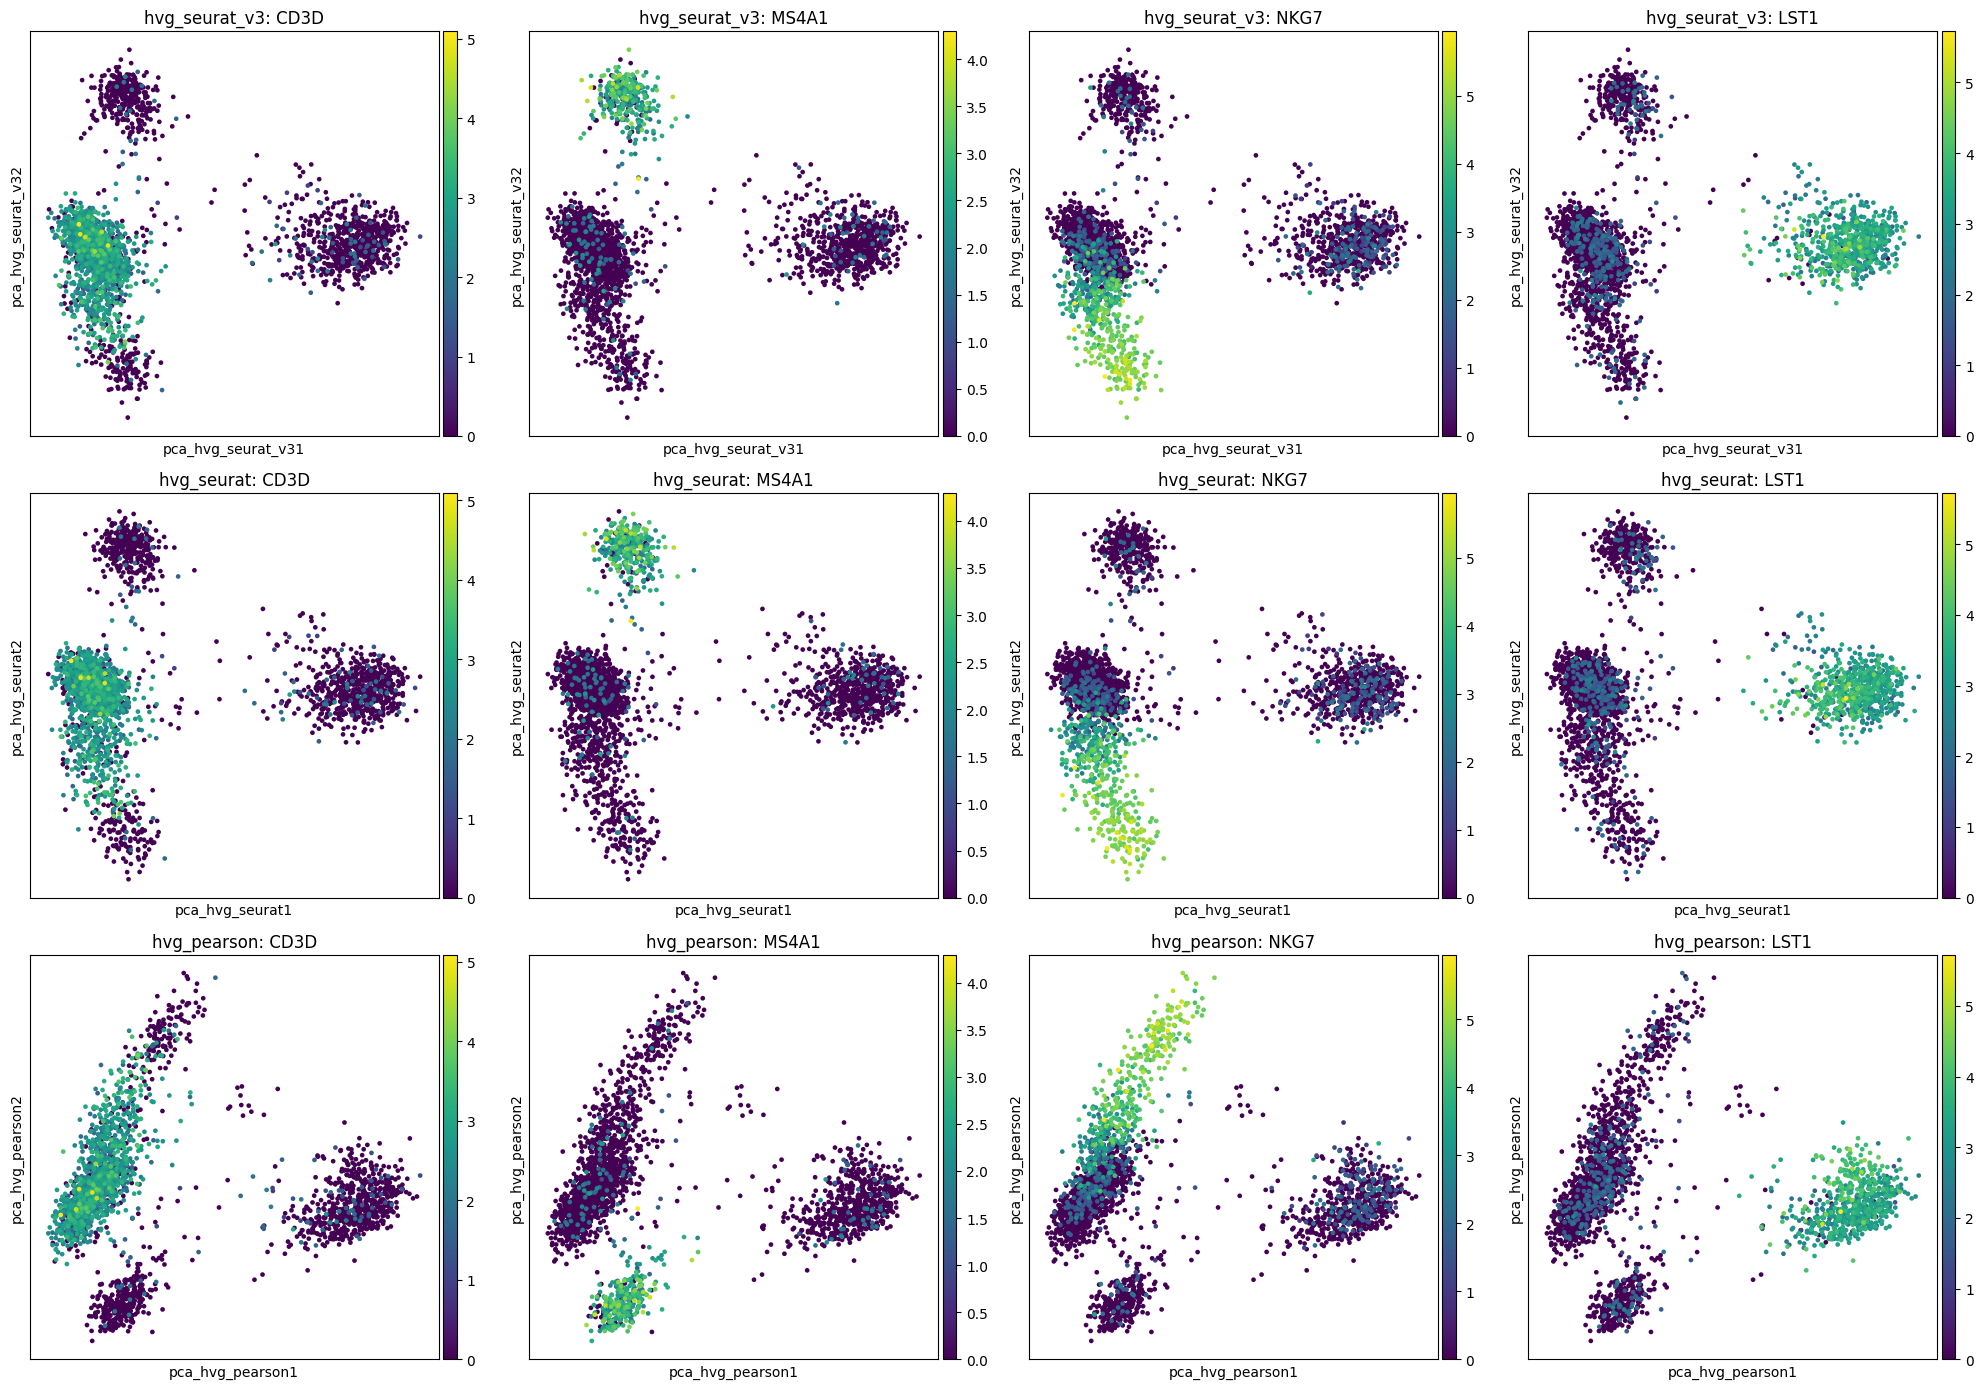

In [ ]:
for m in methods:
    sc.tl.pca(adata, mask_var=m, key_added=f"pca_{m}")
fig, axes = plt.subplots(3, 4, figsize=(20, 14))
for row, m in enumerate(methods):
    for col, gene in enumerate(markers):
        sc.pl.embedding(adata, basis=f"pca_{m}", color=gene, ax=axes[row, col], show=False, title=f"{m}: {gene}")
fig.tight_layout()
plt.show()

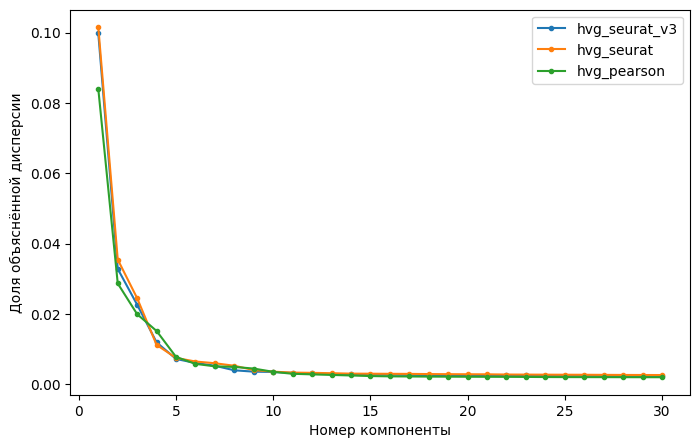

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for m in methods:
    ax.plot(range(1, 31), adata.uns[f"pca_{m}"]["variance_ratio"][:30], marker="o", ms=3, label=m)
ax.set_xlabel("Номер компоненты")
ax.set_ylabel("Доля объяснённой дисперсии")
ax.legend()
plt.show()

* Насколько отличаются расположения клеток?

    Расположение клеток на PCA для seurat_v3 и seurat почти одинаковое, на PCA по Pearson residuals облака клеток имеют немного другую форму, а вторая компонента перевёрнута (B-клетки внизу, NK-клетки вверху) - это не настоящее различие, потому что знак главной компоненты в PCA выбирается произвольно. Взаимное расположение групп во всех трёх случаях одно и то же (PC1 отделяет моноциты от лимфоцитов, PC2 разделяет B- и NK-клетки)


* Сохраняются ли группы клеток с характерной экспрессией маркеров?

    Да. При всех трёх методах видны одни и те же группы: моноциты (LST1), B-клетки (MS4A1), NK-клетки (NKG7) и T-клетки (CD3D), причём T-клетки лежат рядом с NK-клетками ⇒ основная структура данных не зависит от выбора метода отбора HVG

* Сколько генов одновременно попало в оба набора HVG?

    Каждый метод отобрал 2000 генов. В оба набора seurat_v3 и seurat попали 1505 генов (75%), в  пересечение seurat_v3 с Pearson residuals - 1402 гена, seurat с Pearson residuals - 1291. Во всех трёх наборах одновременно 1145 генов

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


In [ ]:
sc.tl.pca(adata, mask_var="hvg_seurat_v3", key_added="pca_hvg")
sc.tl.pca(adata, mask_var=None, key_added="pca_all")

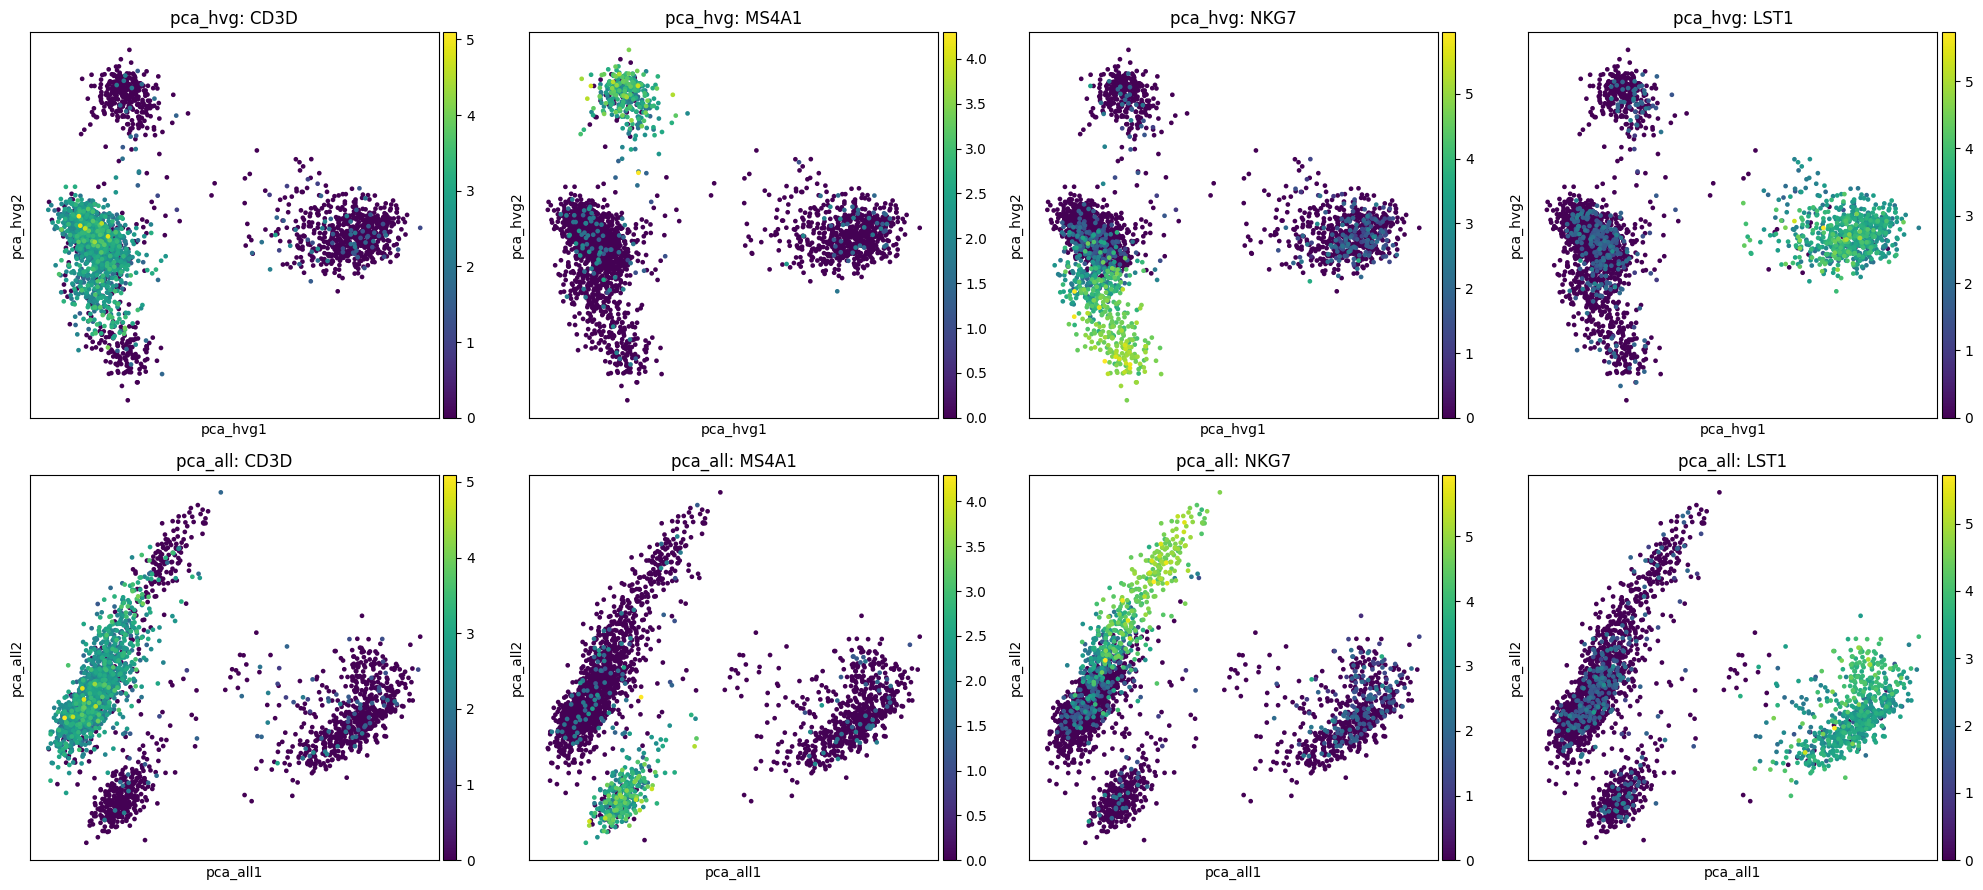

In [ ]:
markers = ["CD3D", "MS4A1", "NKG7", "LST1"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for row, key in enumerate(["pca_hvg", "pca_all"]):
    for col, gene in enumerate(markers):
        sc.pl.embedding(adata, basis=key, color=gene, ax=axes[row, col], show=False, title=f"{key}: {gene}")
fig.tight_layout()
plt.show()

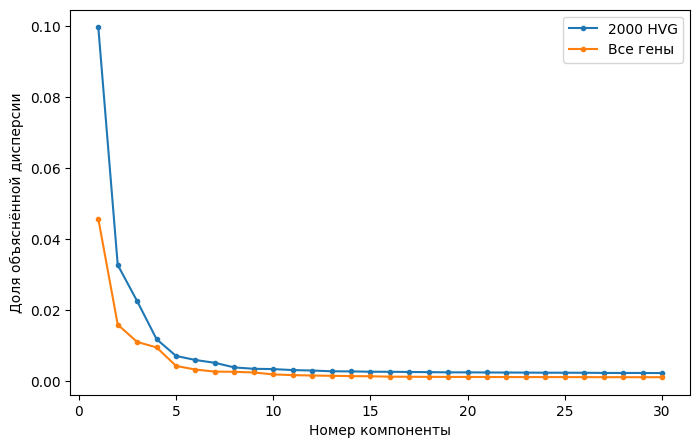

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for key, label in [("pca_hvg", "2000 HVG"), ("pca_all", "Все гены")]:
    ax.plot(range(1, 31), adata.uns[key]["variance_ratio"][:30], marker="o", ms=3, label=label)
ax.set_xlabel("Номер компоненты")
ax.set_ylabel("Доля объяснённой дисперсии")
ax.legend()
plt.show()

* Как изменилась структура клеток?

    Основная структура сохранилась. В обоих PCA моноциты (LST1) отделены от лимфоцитов по PC1, а B-клетки (MS4A1) и NK-клетки (NKG7) расходятся по PC2. PC1 в двух PCA практически совпадает (корреляция координат клеток 0,99) По всем генам PC2 перевёрнута. Заметное отличие в том, что на PCA по всем генам группы клеток более размытые и вытянутые, а T- и NK-клетки слились в одно облако

* Какие компоненты объясняют больше дисперсии?

    Больше дисперсии объясняют компоненты PCA по 2000 HVG. PC1 по HVG объясняет 10% дисперсии против 4,6% по всем генам, первые 10 компонент - 19,7% против 10%, примерно в два раза отличается доля и у остальных компонент

* Почему использование всех доступных генов не обязательно делает PCA информативнее?

    Большинство генов экспрессируются одинаково во всех клетках или настолько слабо, что их вариабельность в основном техническая. Такие гены не несут информации о различиях между клетками, но добавляют шум в общую дисперсию. Отбор HVG оставляет гены, по которым клетки действительно различаются, поэтому группы клеток разделяются чётче, а вычисления идут быстрее

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


In [ ]:
import pandas as pd #среднее и дисперсия по сырым counts

counts = adata.layers["counts"]
mean = np.asarray(counts.mean(axis=0)).ravel()
mean_sq = np.asarray(counts.multiply(counts).mean(axis=0)).ravel()

genes = pd.DataFrame({
    "mean": mean,
    "var": mean_sq - mean**2,
    "pct_cells": np.asarray((counts > 0).mean(axis=0)).ravel() * 100,
    "hvg": adata.var["hvg_seurat_v3"].to_numpy(),
}, index=adata.var_names)
genes["var_to_mean"] = genes["var"] / genes["mean"].replace(0, np.nan)

In [ ]:
top_hvg = genes[genes["hvg"]].sort_values("mean", ascending=False).head(50)
top_non = genes[~genes["hvg"]].sort_values("mean", ascending=False).head(50)

cols = ["mean", "var", "var_to_mean", "pct_cells"]
pd.DataFrame({"HVG": top_hvg[cols].median(), "не HVG": top_non[cols].median()}).round(2)

,HVG,не HVG
mean,2.63,12.93
var,29.46,67.72
var_to_mean,10.31,5.72
pct_cells,59.61,99.22


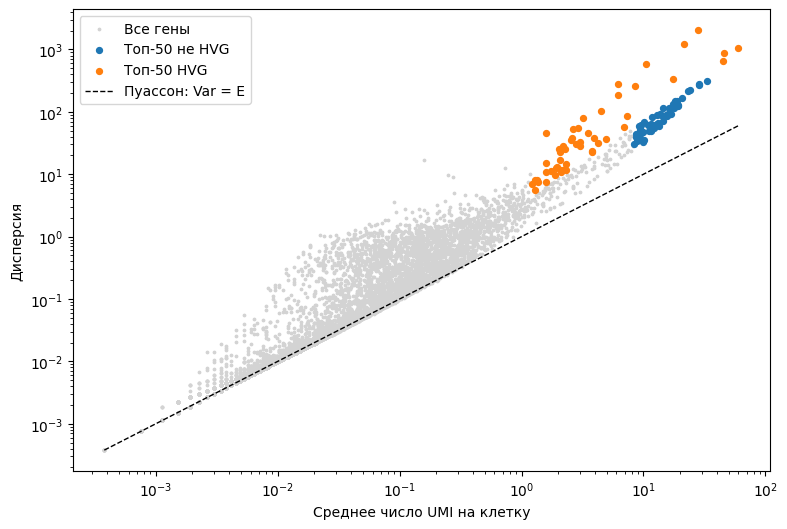

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
nz = genes[genes["mean"] > 0]
ax.scatter(nz["mean"], nz["var"], s=3, c="lightgrey", label="Все гены")
ax.scatter(top_non["mean"], top_non["var"], s=18, label="Топ-50 не HVG")
ax.scatter(top_hvg["mean"], top_hvg["var"], s=18, label="Топ-50 HVG")
x = np.geomspace(nz["mean"].min(), nz["mean"].max(), 100)
ax.plot(x, x, "k--", lw=1, label="Пуассон: Var = E")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Среднее число UMI на клетку")
ax.set_ylabel("Дисперсия")
ax.legend()
plt.show()

* Обязательно ли HVG являются наиболее экспрессируемыми генами?

    Нет. У 50 самых экспрессируемых HVG медиана среднего числа UMI на клетку 2,6, а у 50 самых экспрессируемых генов, не попавших в HVG - 12,9 (в 5 раз больше) Отбор HVG оценивает не уровень экспрессии, а то, насколько дисперсия гена превышает ожидаемую при его среднем уровне

* Почему ген может иметь очень высокую экспрессию, но не попасть в HVG?

    В count-данных дисперсия растёт вместе со средним, поэтому сильно экспрессируемый ген всегда имеет большую абсолютную дисперсию. Если ген экспрессируется примерно одинаково во всех клетка - его дисперсия не превышает ожидаемую для такого среднего (например у рибосомных генов отношение дисперсии к среднему около 6–9, у топ-50 HVG медиана 10.3, а у ферритинов FTL и FTH1, которые особенно высоко экспрессируются в моноцитах, 57–73) На графике гены не из HVG лежат вдоль общего тренда, а HVG заметно выше него + гены не из HVG найдены почти в каждой клетке, а HVG лишь в части

* Какие группы генов встречаются среди наиболее экспрессируемых?


In [ ]:
print("Топ-50 HVG:")
print(list(top_hvg.index))
print("\nТоп-50 не HVG:")
print(list(top_non.index))

Топ-50 HVG:
['MALAT1', 'TMSB4X', 'B2M', 'FTL', 'FTH1', 'ACTB', 'LYZ', 'CD74', 'S100A4', 'MT-CO2', 'HLA-DRA', 'S100A9', 'OAZ1', 'CST3', 'S100A6', 'LTB', 'SH3BGRL3', 'VIM', 'TYROBP', 'S100A8', 'LGALS1', 'COTL1', 'HLA-DPB1', 'SAT1', 'NKG7', 'HLA-DPA1', 'HLA-DRB1', 'CD37', 'IFITM2', 'AIF1', 'ARPC1B', 'LST1', 'IL32', 'UBB', 'FCER1G', 'CTSS', 'CCL5', 'S100A11', 'SRGN', 'S100A10', 'PSAP', 'GNLY', 'KLF6', 'ANXA1', 'FCN1', 'RBM3', 'GSTP1', 'GPX1', 'EIF3H', 'TYMP']

Топ-50 не HVG:
['RPL10', 'RPL13', 'RPL13A', 'RPS2', 'RPS6', 'RPS18', 'RPL11', 'RPL32', 'RPS3', 'RPL19', 'RPS12', 'RPLP1', 'RPL3', 'RPS27', 'RPS19', 'RPS14', 'EEF1A1', 'RPL18A', 'RPL28', 'MT-CO1', 'RPS4X', 'TMSB10', 'RPLP2', 'RPL21', 'RPL15', 'RPS3A', 'RPS15A', 'RPL23A', 'RPS27A', 'RPL12', 'RPL27A', 'RPL6', 'RPS8', 'RPL26', 'TPT1', 'RPS15', 'RPL14', 'RPL10A', 'RPL9', 'RPS7', 'RPL8', 'RPS9', 'RPS16', 'RPL29', 'RPS5', 'RPS23', 'RPL30', 'RPL7', 'RPL18', 'PTMA']


In [ ]:
print("Рибосомных среди не HVG:", top_non.index.str.match(r"^RP[SL]").sum())
print("Рибосомных среди HVG:", top_hvg.index.str.match(r"^RP[SL]").sum())

Рибосомных среди не HVG: 45
Рибосомных среди HVG: 0


Среди 50 наиболее экспрессируемых генов, не попавших в HVG, 45 кодируют белки рибосомы (`RPL…`, `RPS…`). Оставшиеся пять (`EEF1A1`, `TPT1`, `PTMA`, `TMSB10`, `MT-CO1`) тоже обеспечивают базовые функции клетки: трансляцию, рост, работу цитоскелета и дыхание. Это гены домашнего хозяйства, которые одинаково экспрессируются во всех клетках. Среди 50 наиболее экспрессируемых HVG рибосомных генов нет, а преобладают маркеры клеточных популяций: моноцитов (`LYZ`, `S100A8`, `S100A9`, `CST3`), антигенпрезентирующих клеток (`CD74`, `HLA-DRA`), NK-клеток и цитотоксических T-клеток (`NKG7`, `GNLY`, `CCL5`) и T-клеток (`LTB`, `IL32`).

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

In [ ]:
#исходные данные и QC-метрики
raw = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
raw.var["mt"] = raw.var_names.str.startswith("MT-")
raw.var["ribo"] = raw.var_names.str.match(r"^RP[SL]\d+[AXYL]?L?\d*$|^RPLP\d$|^RPSA$")
sc.pp.calculate_qc_metrics(raw, qc_vars=["mt", "ribo"], percent_top=None, log1p=False, inplace=True)

In [ ]:
def run_pca(adata, qc, hvg):
    adata = adata.copy()
    if qc:
        sc.pp.filter_cells(adata, min_genes=200)
        sc.pp.filter_genes(adata, min_cells=3)
        adata = adata[(adata.obs["n_genes_by_counts"] < 2500) & (adata.obs["pct_counts_mt"] < 5)].copy()
    adata.layers["counts"] = adata.X.copy()
    if hvg:
        sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    sc.tl.pca(adata, mask_var="highly_variable" if hvg else None)
    return adata

cases = {
    "1. без QC, без HVG": run_pca(raw, qc=False, hvg=False),
    "2. без QC, с HVG": run_pca(raw, qc=False, hvg=True),
    "3. с QC, без HVG": run_pca(raw, qc=True, hvg=False),
    "4. с QC, с HVG": run_pca(raw, qc=True, hvg=True),
}

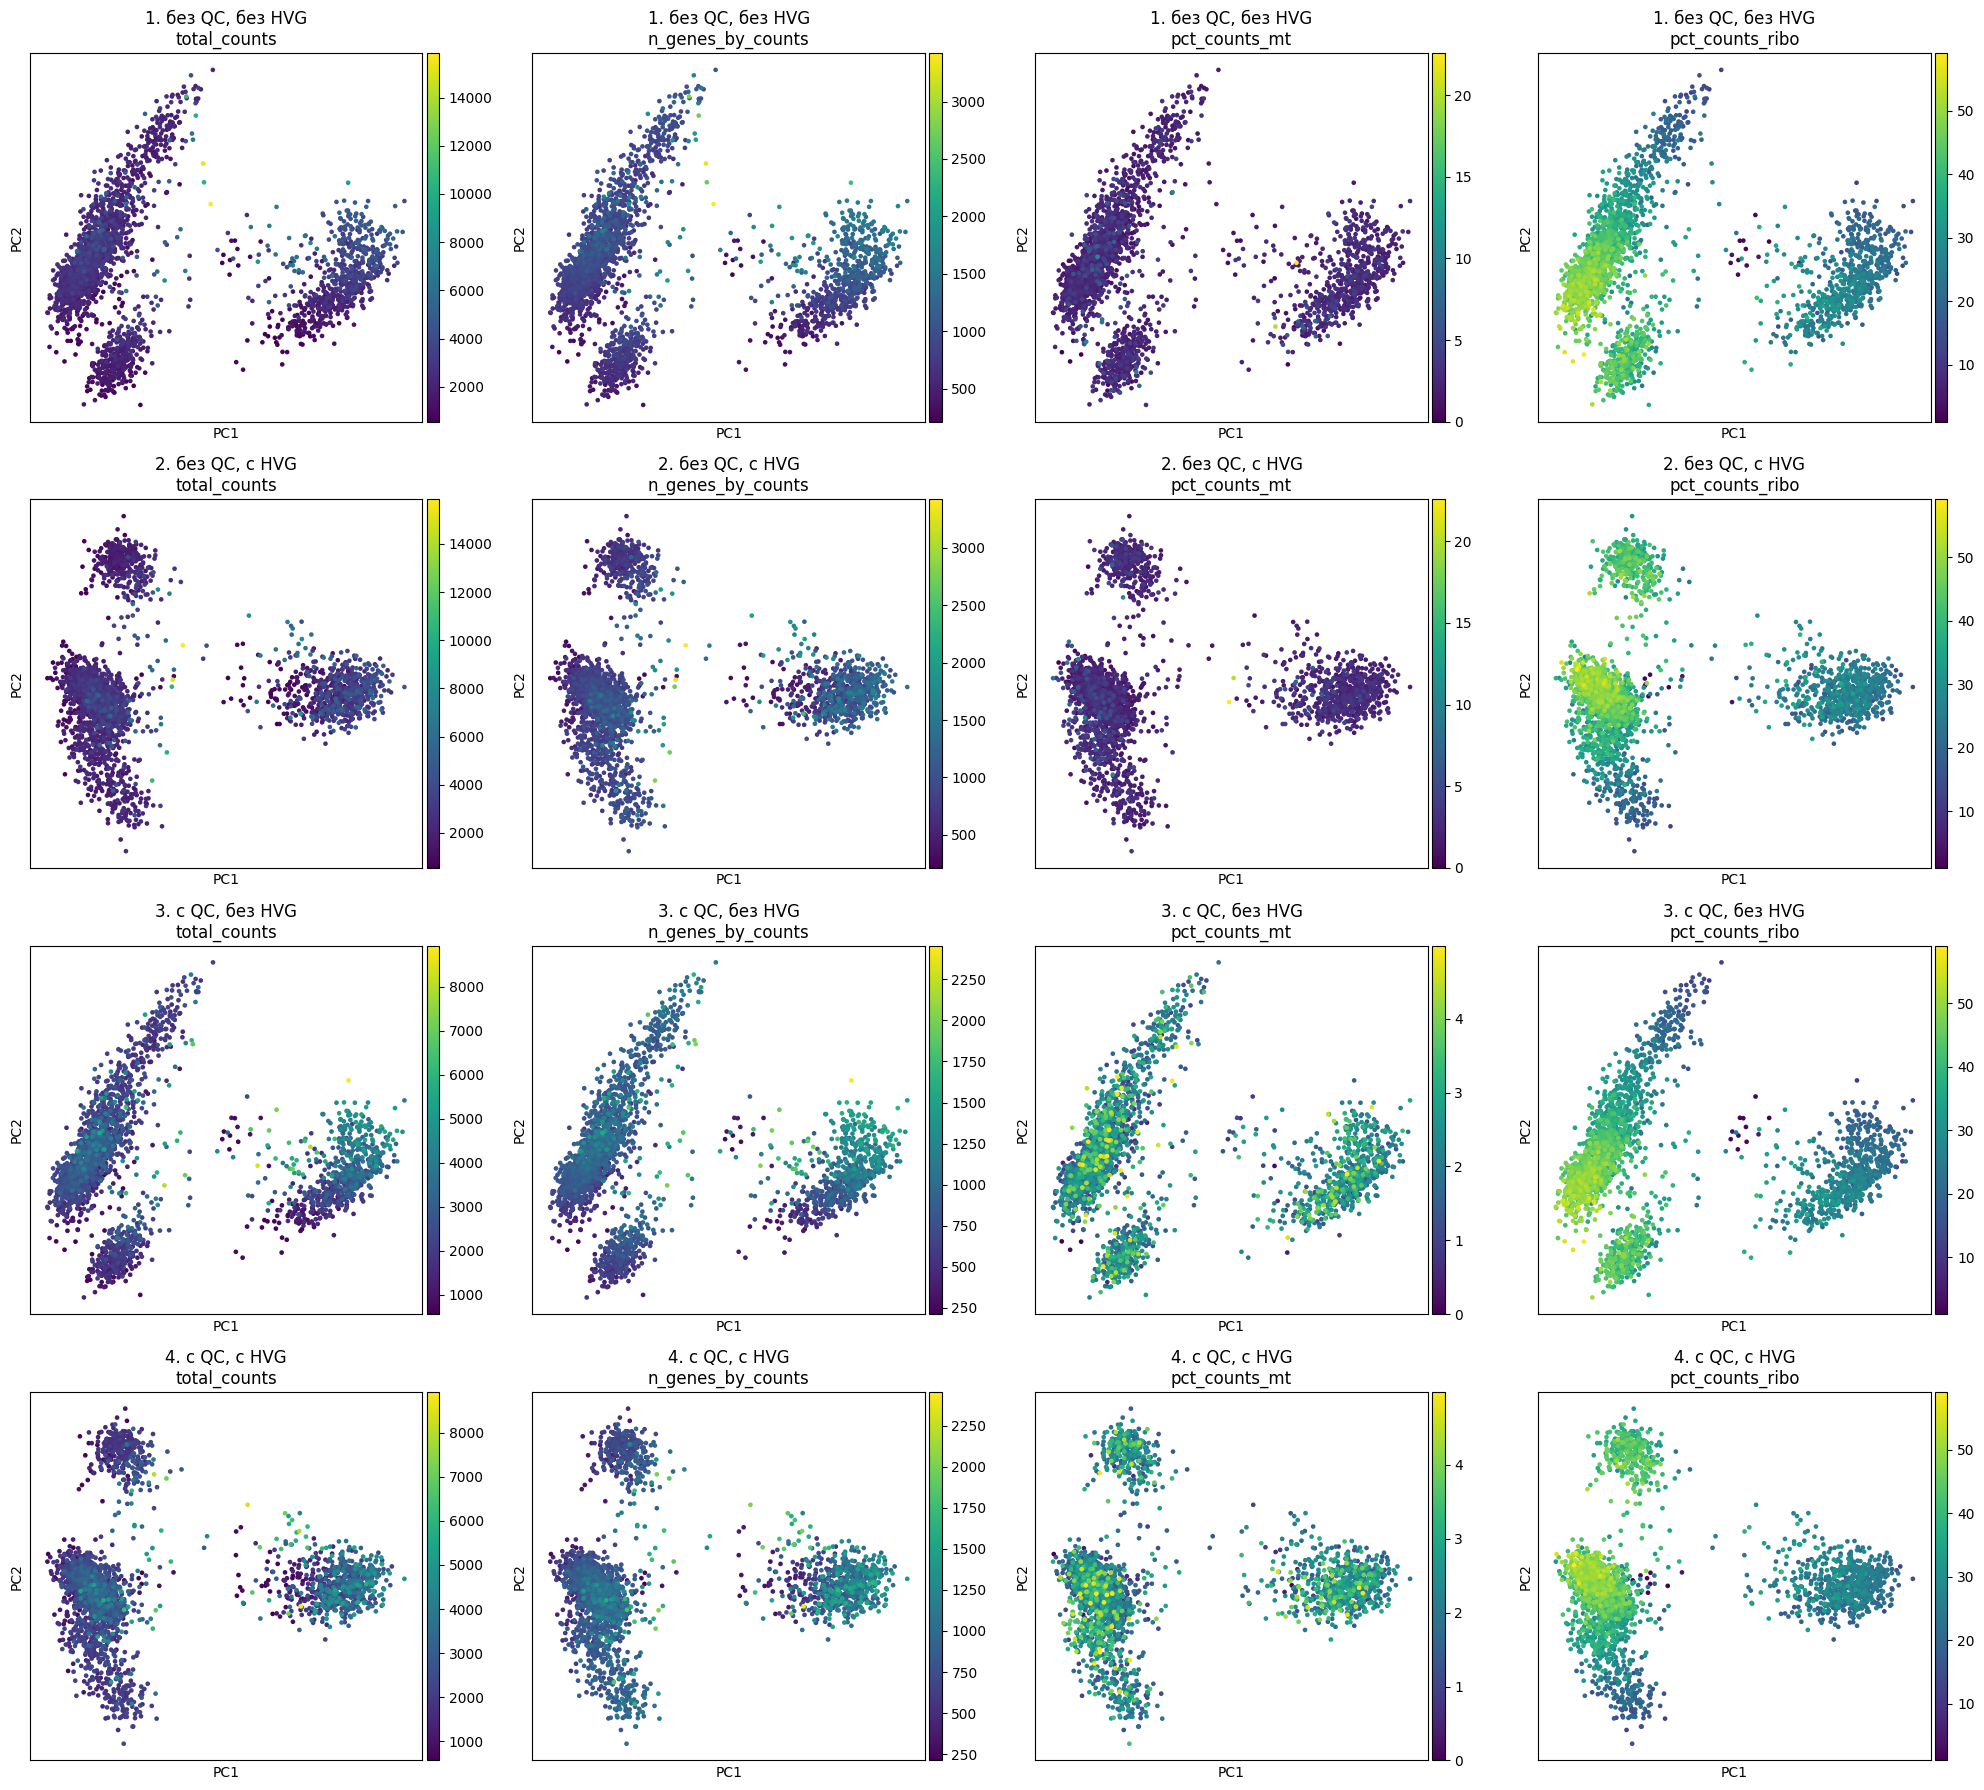

In [ ]:
#PCA окрашенные по qc метрикам
colors = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]

fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for row, (name, ad) in enumerate(cases.items()):
    for col, c in enumerate(colors):
        sc.pl.pca(ad, color=c, ax=axes[row, col], show=False, title=f"{name}\n{c}")
fig.tight_layout()
plt.show()

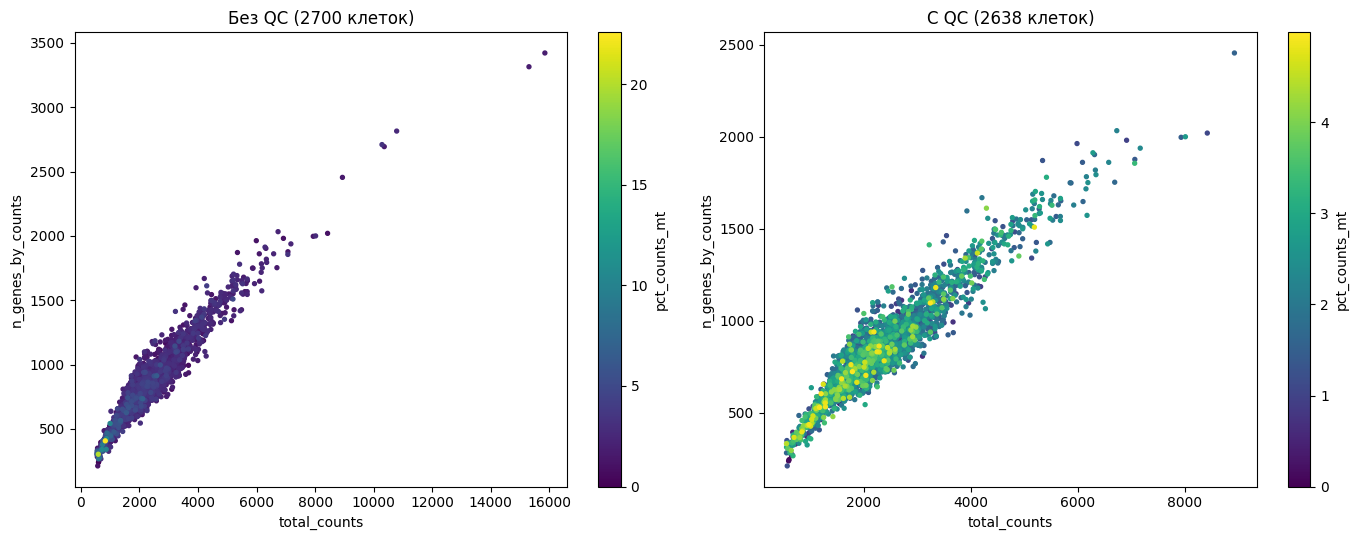

In [ ]:
#scatter до и после qc
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, ad) in zip(axes, [("Без QC", raw), ("С QC", cases["4. с QC, с HVG"])]):
    obs = ad.obs.sort_values("pct_counts_mt")
    points = ax.scatter(obs["total_counts"], obs["n_genes_by_counts"], c=obs["pct_counts_mt"], s=8)
    fig.colorbar(points, ax=ax, label="pct_counts_mt")
    ax.set_xlabel("total_counts")
    ax.set_ylabel("n_genes_by_counts")
    ax.set_title(f"{title} ({ad.n_obs} клеток)")
fig.tight_layout()
plt.show()

* Связано ли положение клеток на PCA с количеством зарегистрированных UMI?

    Частично да. У моноцитов (правое облако) в целом больше UMI и генов, чем у лимфоцитов, поэтому PC1 слабо связана с total_counts, это скорее различие между типами клеток, а не техника. Заметнее связь внутри облаков. На PCA без HVG облако лимфоцитов вытянуто, и вдоль него число UMI и генов плавно растёт

* Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов?

    Выраженных направлений нет. Клетки с повышенной долей митохондриальных UMI рассеяны по всем группам, а корреляция pct_counts_mt с первыми компонентами не превышает 0,26. Без QC единичные клетки с высокой долей видны как отдельные точки, но отдельной группы не образуют, тк их всего несколько десятков

* Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

    В принципе можно. Глубина секвенирования (total_counts, n_genes_by_counts) задаёт одну из первых компонент: PC3 без HVG и PC4 с HVG. Это технический источник вариации, который может смешиваться с биологическим. Первые две компоненты определяются в основном типом клеток. Сильная связь доли рибосомных UMI с PC1 (корреляция около −0,7) тоже объясняется биологией: у лимфоцитов рибосомных UMI больше, чем у моноцитов. Также доля митохондриальных UMI на главные компоненты заметно не влияет


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

In [ ]:
ad = cases["4. с QC, с HVG"]
loadings = pd.DataFrame(ad.varm["PCs"][:, :2], index=ad.var_names, columns=["PC1", "PC2"])

for pc in ["PC1", "PC2"]:
    s = loadings[pc].sort_values()
    print(pc, "положительные:", list(s.index[-10:][::-1]))
    print(pc, "отрицательные:", list(s.index[:10]))

PC1 положительные: ['LYZ', 'CST3', 'S100A9', 'TYROBP', 'S100A8', 'LGALS1', 'AIF1', 'LST1', 'FCER1G', 'FCN1']
PC1 отрицательные: ['LTB', 'IL32', 'MALAT1', 'IL7R', 'CCL5', 'CD2', 'CTSW', 'STK17A', 'ACAP1', 'CD247']
PC2 положительные: ['HLA-DRA', 'CD74', 'HLA-DPB1', 'HLA-DRB1', 'CD79A', 'HLA-DPA1', 'HLA-DQA1', 'HLA-DQB1', 'CD79B', 'HLA-DRB5']
PC2 отрицательные: ['NKG7', 'S100A4', 'CCL5', 'IL32', 'GNLY', 'CTSW', 'GZMA', 'CST7', 'SRGN', 'ANXA1']


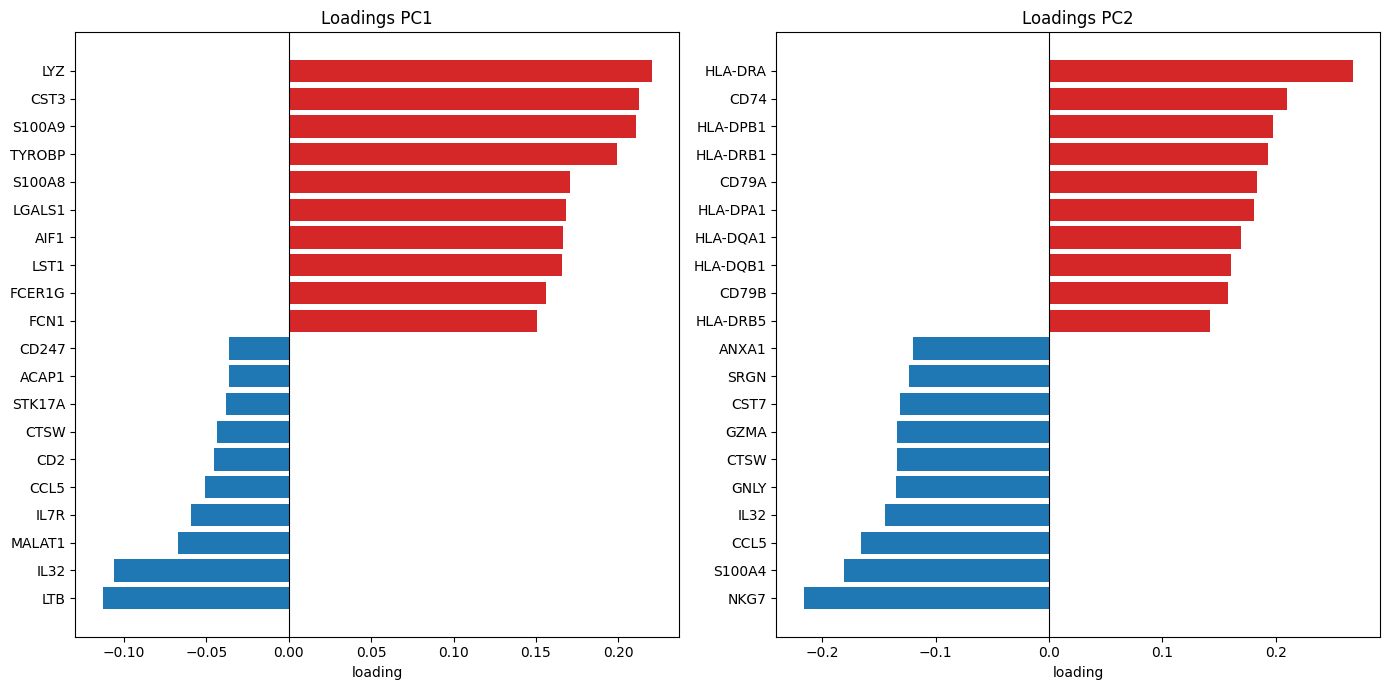

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    s = loadings[pc].sort_values()
    sel = pd.concat([s.head(10), s.tail(10)])
    ax.barh(sel.index, sel.values, color=["tab:blue"] * 10 + ["tab:red"] * 10)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Loadings {pc}")
    ax.set_xlabel("loading")
fig.tight_layout()
plt.show()

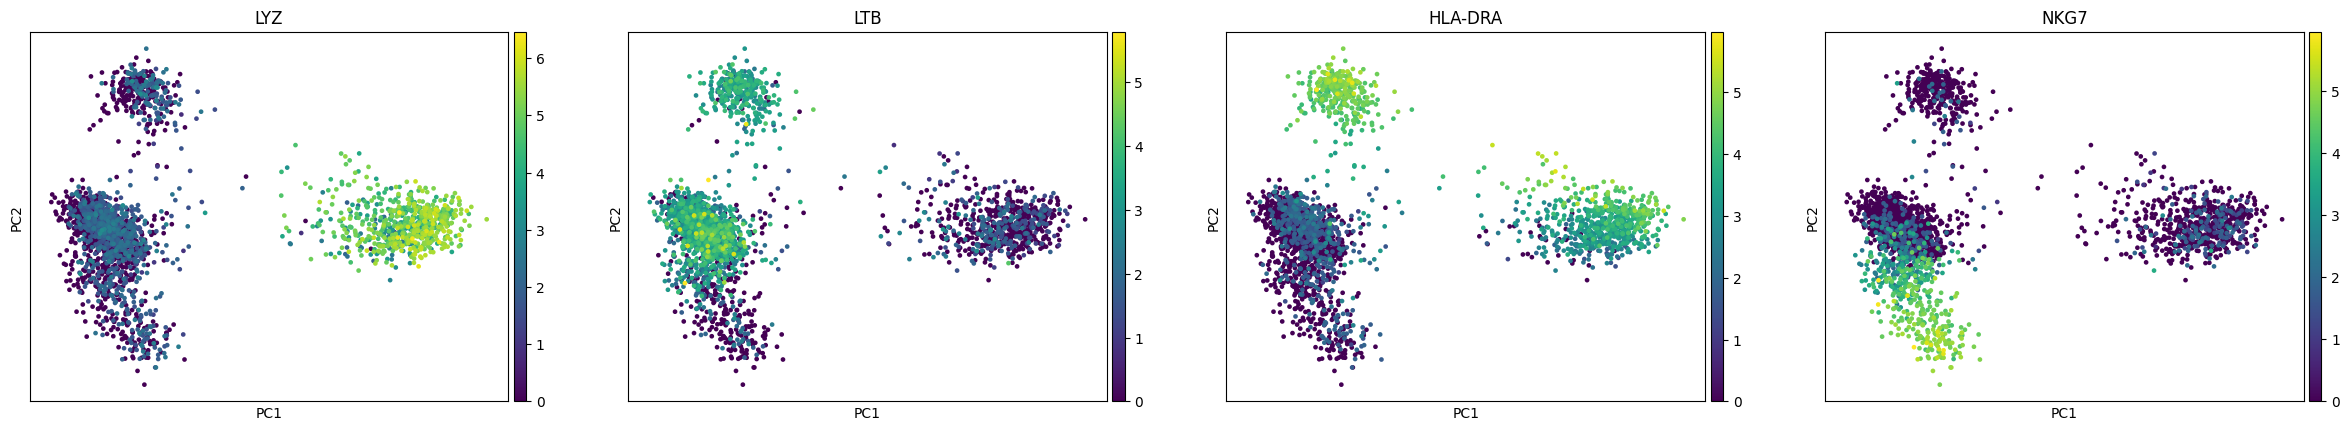

In [ ]:
sc.pl.pca(ad, color=["LYZ", "LTB", "HLA-DRA", "NKG7"]) #взяла одному гену с самым большим по модулю loading с каждой стороны PC1 и PC2

* Какие гены сильнее всего определяют PC1 и PC2?

    PC1 сильнее всего определяют маркеры моноцитов: LYZ, CST3, S100A9, TYROBP и S100A8, на противоположной стороне PC1 лежат гены T-клеток LTB, IL32, IL7R, CD2, но их loadings меньше (до −0,11). PC2 определяют молекулы MHC II класса и B-клеточного рецептора (HLA-DRA, CD74, HLA-DPB1, CD79A, CD79B) и с другой стороны гены цитотоксических клеток (NKG7, S100A4, CCL5, GNLY, GZMA)

* Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками?

    Почти все эти гены являются маркерами иммунных популяций. Генов клеточного цикла (например, MKI67 или TOP2A) среди них нет, что ожидаемо для зрелых клеток крови, которые почти не делятся. Нет и митохондриальных или рибосомных генов, те QC-метрики главные компоненты напрямую не определяют. Единственное исключение - MALAT1 среди отрицательных генов PC1 - это ядерная РНК, которую используют и как QC-метрику, но здесь она скорее всего отражает тип клеток (в лимфоцитах её больше, чем в моноцитах)

* Можно ли биологически интерпретировать главные компоненты на основании этих генов?

    Да. PC1 разделяет моноциты и лимфоциты, а PC2  B- и NK-клетки + цитотоксические T-клетки. Это подтверждают графики экспрессии (LYZ высоко экспрессирован в облаке моноцитов, LTB  в облаке лимфоцитов, HLA-DRA  в B-клетках и моноцитах, NKG7 в нижней части облака лимфоцитов)

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток.

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

In [ ]:
base = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
base.var["mt"] = base.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(base, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
sc.pp.filter_cells(base, min_genes=200)
sc.pp.filter_genes(base, min_cells=3)
base = base[(base.obs.n_genes_by_counts < 2500) & (base.obs.pct_counts_mt < 5)].copy()
base.layers["counts"] = base.X.copy()
sc.pp.highly_variable_genes(base, layer="counts", flavor="seurat_v3", n_top_genes=2000)

In [ ]:
def prep(normalize, log, scale):
    ad = base.copy()
    if normalize:
        sc.pp.normalize_total(ad, target_sum=1e4)
    if log:
        sc.pp.log1p(ad)
    if scale:
        sc.pp.scale(ad)
    sc.tl.pca(ad, mask_var="highly_variable")
    return ad

variants = {
    "normalize + log1p": prep(True, True, False),
    "только normalize": prep(True, False, False),
    "без normalize и log1p": prep(False, False, False),
    "normalize + log1p + scale": prep(True, True, True)}

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


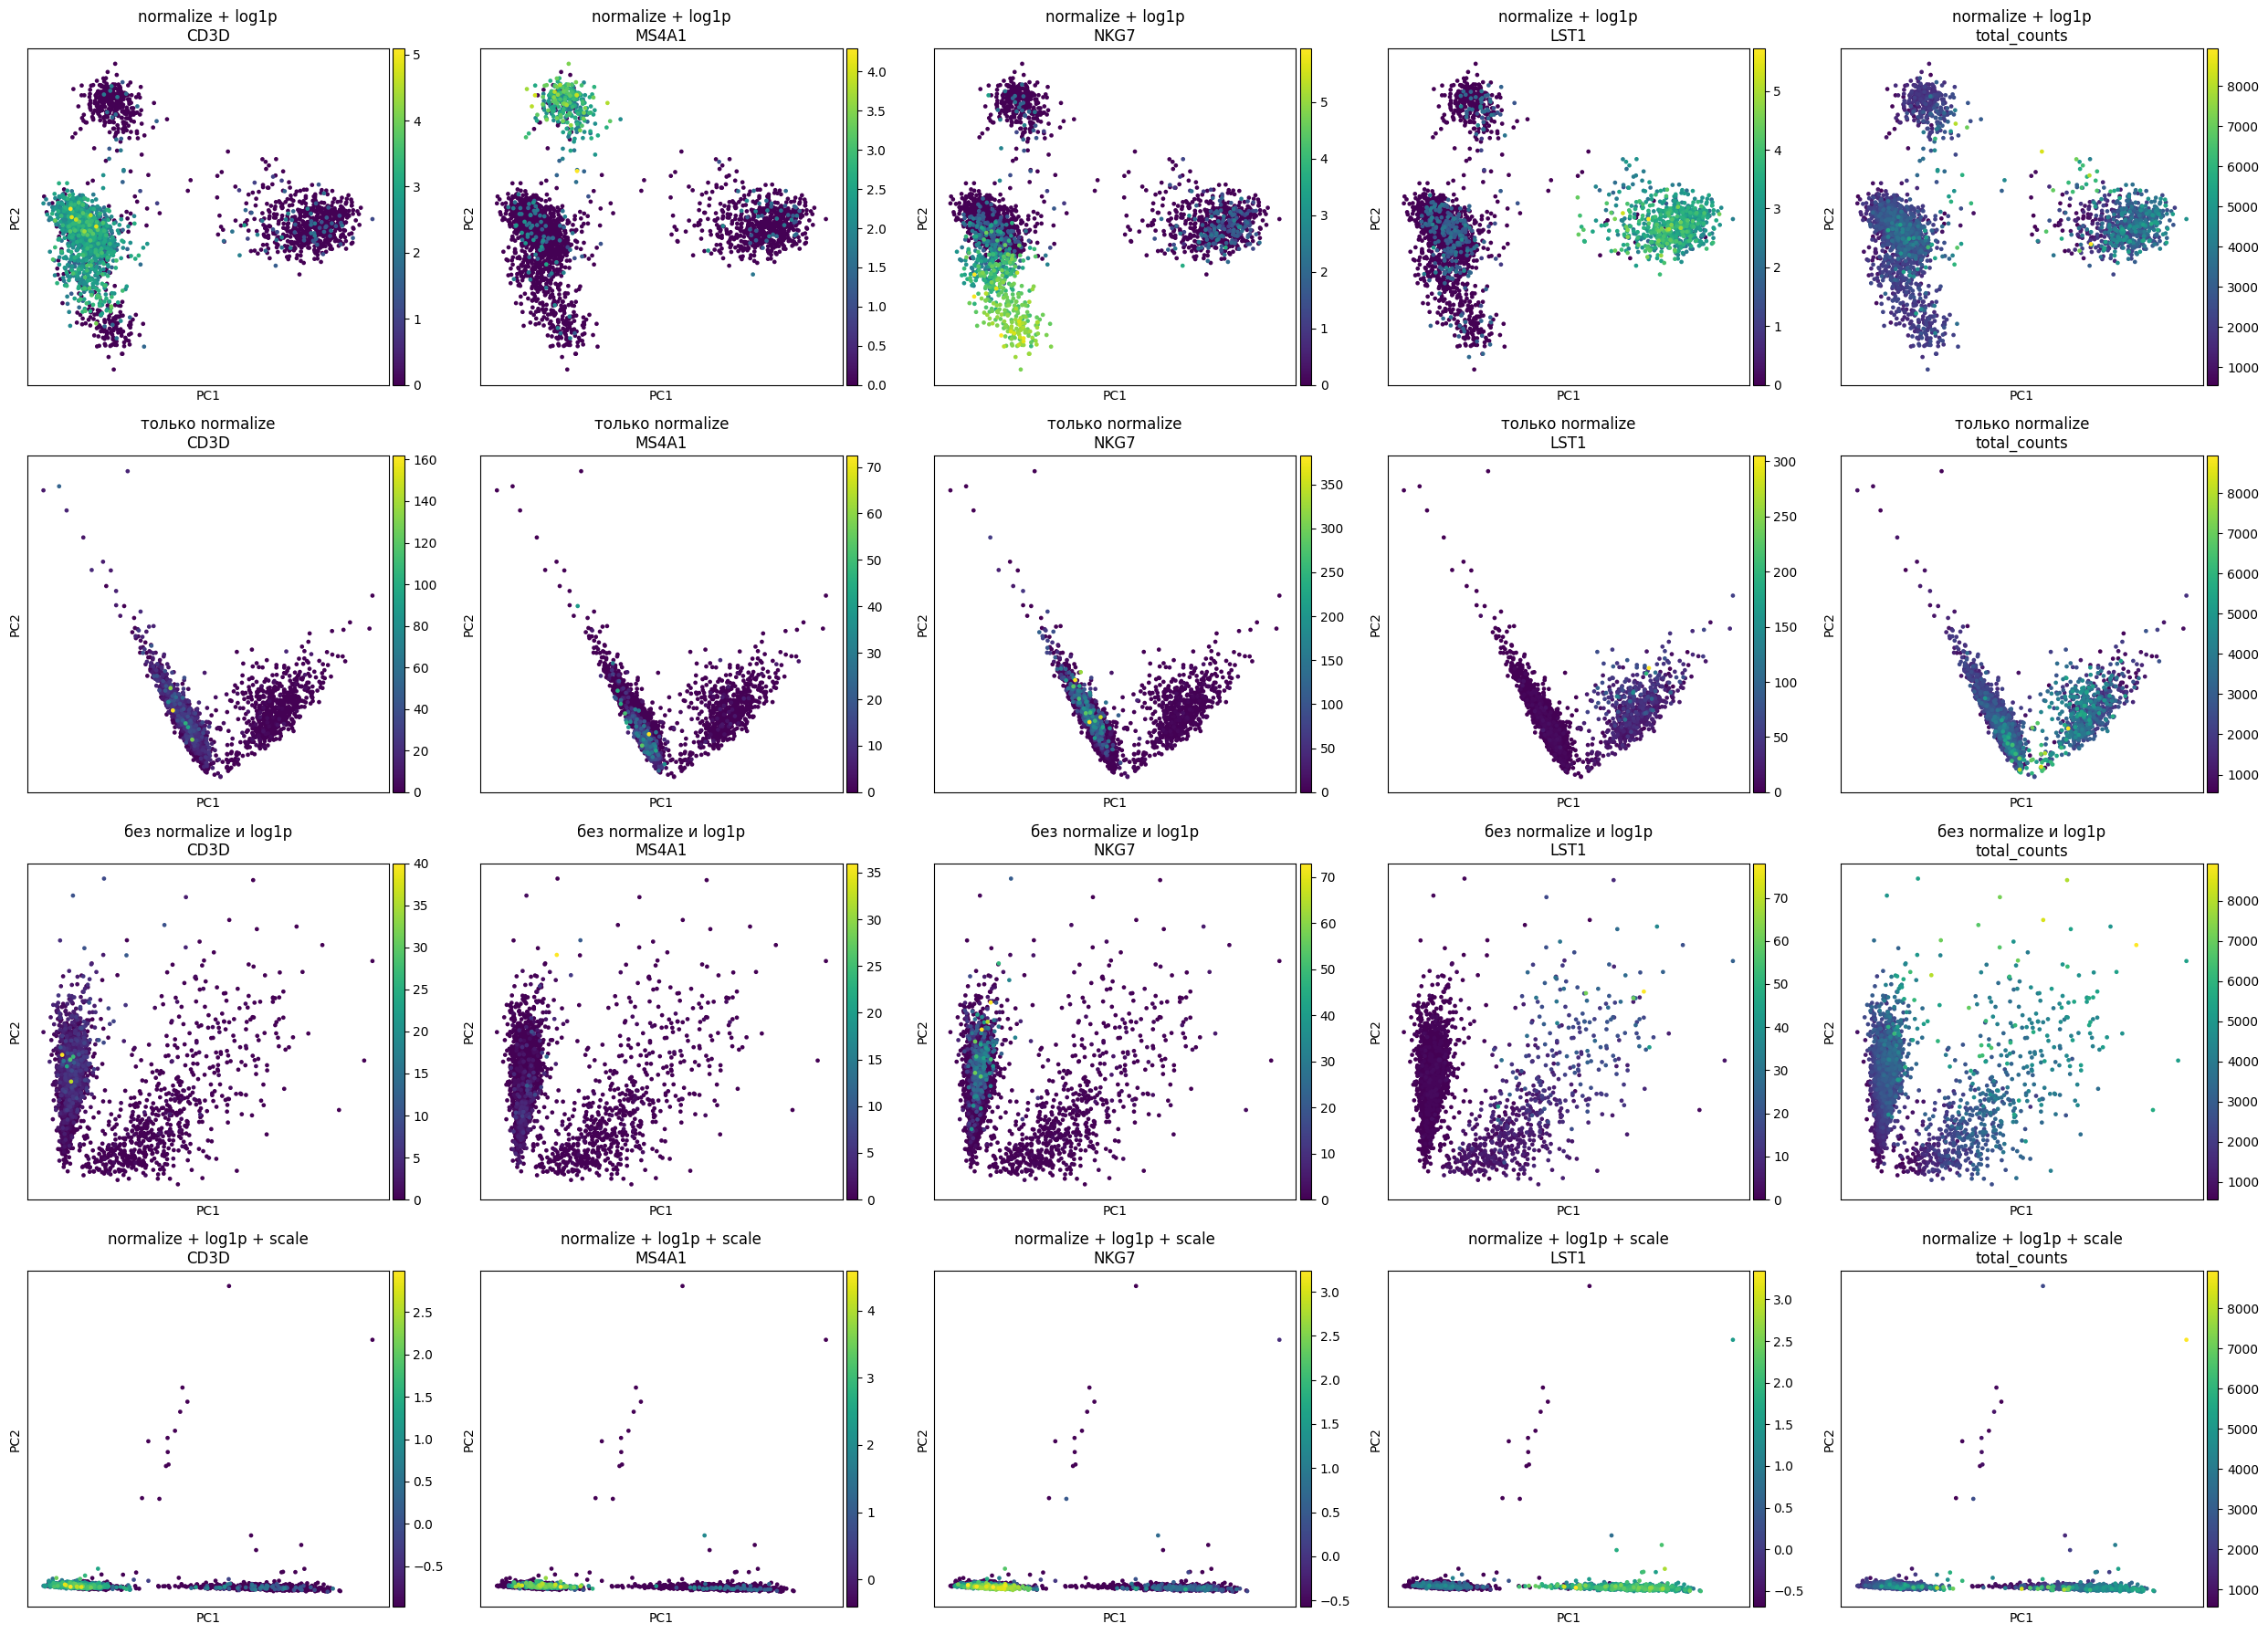

In [ ]:
colors = ["CD3D", "MS4A1", "NKG7", "LST1", "total_counts"] #PCA окрашенные по маркерам и числу umi
fig, axes = plt.subplots(4, 5, figsize=(25, 18))
for r, (name, ad) in enumerate(variants.items()):
    for c, col in enumerate(colors):
        sc.pl.pca(ad, color=col, ax=axes[r, c], show=False, title=f"{name}\n{col}")
fig.tight_layout()
plt.show()

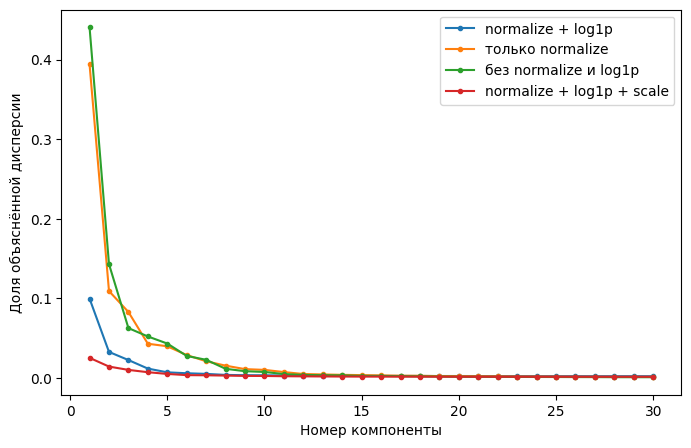

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5)) #доля объясненной дисперсии
for name, ad in variants.items():
    ax.plot(range(1, 31), ad.uns["pca"]["variance_ratio"][:30], marker="o", ms=3, label=name)
ax.set_xlabel("Номер компоненты")
ax.set_ylabel("Доля объяснённой дисперсии")
ax.legend()
plt.show()

* Что сильнее влияет на PCA — нормализация или логарифмирование?

    Сильнее влияет логарифмирование. Без него PCA плохая даже при нормализации (видно только разделение моноцитов и лимфоцитов, а 87% веса PC1 приходится всего на 5 генов с самой высокой экспрессией) Нормализация без логарифмирования лишь ослабляет связь главных компонент с числом UMI, но структуру популяций не восстанавливает

* Сильно ли помогает scale?

    Для этих данных не помогает. После стандартизации ни один ген не доминирует, но PC2 стали определять гены тромбоцитов (PF4, GP9, PPBP), экспрессирующиеся лишь в нескольких клетках. Эти клетки вытягиваются в отдельный «хвост», а остальные сжимаются в полосу, и разделение популяций на PC1–PC2 становится хуже, чем без scale

* Что даёт каждая процедура и как она влияет на PCA?

    1)Нормализация выравнивает клетки по глубине секвенирования. Без неё главные компоненты отражают число UMI в клетке, то есть технический фактор, а не биологию.
    
    2)Логарифмирование (log1p) сжимает диапазон значений и уменьшает связь дисперсии со средним (без него PCA определяют несколько самых сильно экспрессируемых генов, а слабее экспрессируемые маркеры почти не вносят вклада)
    
    3)Стандартизация приводит каждый ген к среднему 0 и дисперсии 1, поэтому все гены вносят одинаковый вклад (это усиливает слабо экспрессируемые маркеры, но также и редкие гены, экспрессирующиеся в немногих клетках ⇒ PCA становится чувствительной к малым группам клеток и выбросам)

* Все ли процедуры нужно делать перед PCA?

    Нормализация и логарифмирование нужны всегда (без них PCA отражает глубину секвенирования и несколько доминирующих генов) Стандартизация необязательна,она входит в классический пайплайн Seurat и Scanpy, но её применяют с ограничением максимального значения (sc.pp.scale(adata, max_value=10)), чтобы редкие гены не создавали выбросов. В наших данных PCA без стандартизации разделяет популяции лучше

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

In [ ]:
s_genes = ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6",
           "CDCA7", "DTL", "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1",
           "GMNN", "WDR76", "SLBP", "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2",
           "CDC45", "CDC6", "EXO1", "TIPIN", "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1",
           "CHAF1B", "BRIP1", "E2F8"]
g2m_genes = ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2",
             "CKS1B", "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2",
             "AURKB", "BUB1", "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1",
             "CDC20", "TTK", "CDC25C", "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8", "ECT2",
             "KIF23", "HMMR", "AURKA", "PSRC1", "ANLN", "LBR", "CKAP5", "CENPE", "CTCF", "NEK2",
             "G2E3", "GAS2L3", "CBX5", "CENPA"]

s_found = [g for g in s_genes if g in adata.var_names] #оставим только гены которые есть в матрице
g2m_found = [g for g in g2m_genes if g in adata.var_names]
print(len(s_found), "из", len(s_genes), "|", len(g2m_found), "из", len(g2m_genes))

36 из 43 | 44 из 54


In [ ]:
#считаем насколько гены фазы экспрессируются сильнее чем случайные контрольные гены с похожим уровнем экспрессии
sc.tl.score_genes_cell_cycle(adata, s_genes=s_found, g2m_genes=g2m_found)
adata.obs["phase"].value_counts() #по этим оценкам присваиваем каждой клетке фазу

phase
G1     1685
S       866
G2M      87
Name: count, dtype: int64

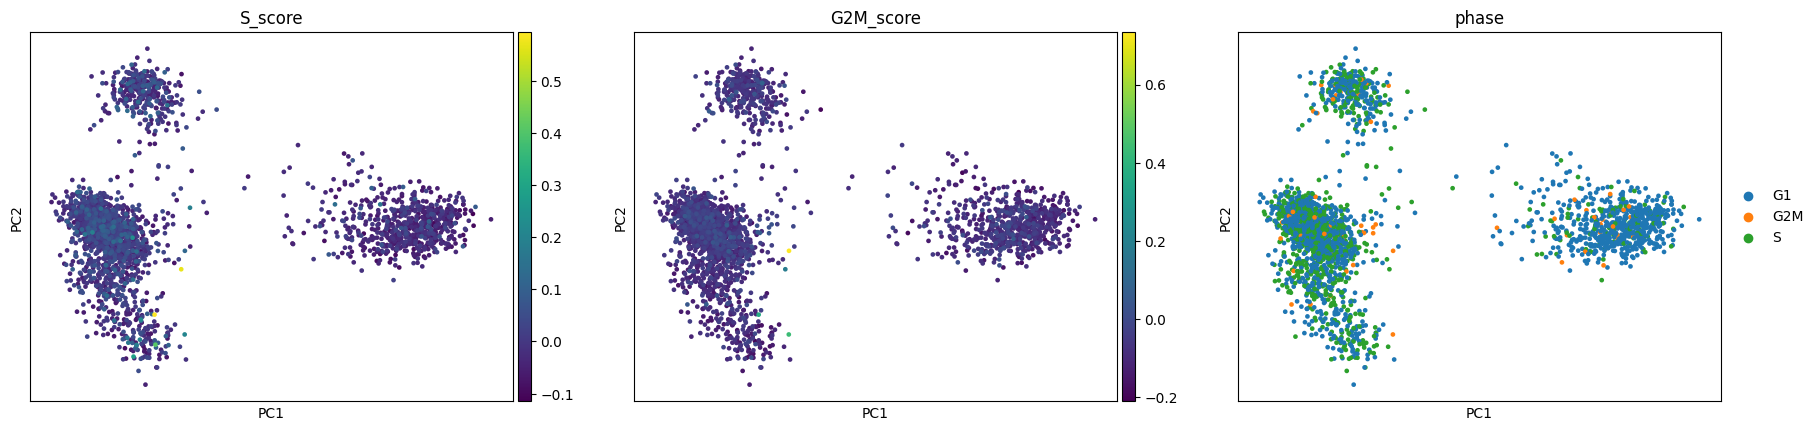

In [ ]:
sc.pl.pca(adata, color=["S_score", "G2M_score", "phase"])

* Разделяются ли клетки по фазам клеточного цикла?

    Нет. На PCA клетки всех трёх фаз перемешаны внутри каждой популяции и отдельных групп не образуют. Яркие точки на графиках S_score и G2M_score с высокими оценками единичны, значит по-настоящему делящихся клеток очень мало и фаза S присваивается многим клеткам из-за небольших случайных отклонений оценки от нуля, а не из-за реального деления

* Можно ли обнаружить связь клеточного цикла с PC1 или PC2?

    Нет. Вдоль PC1 и PC2 не видно ни градиента оценок S_score и G2M_score ни скопления клеток какой-либо фазы. Положение клеток на PCA определяется их типом, а не клеточным циклом

* Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

    Клетки одного типа делятся не синхронно, в каждый момент часть из них находится в G1 а часть в S или G2/M + многие гены клеточного цикла экспрессируются слабо и из-за технического шума их измеренная экспрессия может различаться даже у клеток в одинаковом состоянии